# 04 — Classical models: how good are they, how sure are we, and where do they fail?

`src/train_classic.py` trained one SVM and one Random Forest per protocol and feature set and evaluated each once on the test set. That answers *what score did we get*, but not the questions a reader of the thesis will ask next:

1. Is the score meaningfully above chance and above a simple linear model?
2. Would the ranking of models change with a different split of the artists?
3. Are the differences between models and feature sets larger than what random variation produces?
4. Which hyperparameters and which groups of features matter?
5. Would more data help?
6. Does combining the models help?
7. Which songs are misclassified, and is there a pattern (for example, by genre)?
8. How confident are the models, and what do they cost to train and store?

All heavy computation is done by `src/experiments_classic.py`, which writes its raw outputs to `results/experiments/`. This notebook only reads those files, analyses them and saves the figures and tables to `results/experiments/figures/`.

**Evaluation rule kept throughout.** Every choice (hyperparameters, ensemble members, removed feature groups, training size) is made on the **validation** set. The **test** set of each split is evaluated exactly once per configuration and is never used to choose anything. Ablation and learning curves are therefore reported on validation only.

**Splits.** Protocol A is the official MERGE split `tvt_70_15_15` (artists may appear in several sets). Protocol B is our artist-grouped split (`src/splits.py`, decision D10), generated with five seeds (42–46, decision D12): each seed puts a different set of artists in the test set, and no artist appears in more than one set.

**Models.** `dummy` predicts a class at random with the training class proportions (the chance level); `logreg` is multinomial logistic regression on standardised features (a linear reference); `svm` is an RBF-kernel SVM on standardised features; `rf` is a Random Forest; `vote` is the majority vote of svm, rf and logreg (ties go to the SVM).

**Feature sets.** `base` = 133 librosa features (`src/features.py`); `tonal` = the same plus 22 harmony and tonality features (`src/features_tonal.py`, decision D13).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import auc, confusion_matrix, roc_curve

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
EXP = ROOT / "results" / "experiments"
OUT = EXP / "figures"
OUT.mkdir(parents=True, exist_ok=True)
META = ROOT / "data" / "raw" / "MERGE_Audio_Balanced" / "merge_audio_balanced_metadata.csv"

QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
NAMES = {"Q1": "Q1 happy", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm"}
MODELS = ["dummy", "logreg", "svm", "rf", "vote"]
MODEL_COLORS = {"dummy": "#999999", "logreg": "#56B4E9", "svm": "#0072B2", "rf": "#009E73", "vote": "#E69F00"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
summary = {}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()


runs = pd.read_csv(EXP / "runs.csv")
runs["family"] = np.where(runs["protocol"] == "A", "A", "B")
preds = pd.read_csv(EXP / "test_predictions.csv")
search = pd.read_csv(EXP / "validation_search.csv")
info = json.loads((EXP / "info.json").read_text(encoding="utf-8"))
print(info["created"], "|", info["elapsed_minutes"], "min |", "sklearn", info["sklearn"])
print("Splits:", info["protocols"])

2026-11-21T15:26:55 | 35.2 min | sklearn 1.9.1
Splits: {'A': 'tvt_70_15_15', 'B42': 'artist_70_15_15', 'B43': 'artist_70_15_15_seed43', 'B44': 'artist_70_15_15_seed44', 'B45': 'artist_70_15_15_seed45', 'B46': 'artist_70_15_15_seed46'}


## 1. Main comparison: chance level, linear reference, SVM, RF, ensemble

**Purpose:** place every model on the same scale. For protocol A there is one test set, so one number per model. For protocol B there are five test sets (one per seed), so we report the mean and the standard deviation over the five seeds; the standard deviation shows how much the score depends on which artists ended up in the test set.

In [2]:
table = (runs.groupby(["family", "feature_set", "model"])["test_macro_f1"]
         .agg(["mean", "std", "count"]).reset_index())
table["model"] = pd.Categorical(table["model"], MODELS, ordered=True)
table = table.sort_values(["family", "feature_set", "model"])
wide = table.pivot_table(index="model", columns=["family", "feature_set"], values=["mean", "std"], observed=True)
pretty = pd.DataFrame(index=wide.index)
for fam, fs in [("A", "base"), ("A", "tonal"), ("B", "base"), ("B", "tonal")]:
    m, s = wide[("mean", fam, fs)], wide.get(("std", fam, fs))
    pretty[f"{fam} {fs}"] = [f"{a:.3f}" if fam == "A" else f"{a:.3f} ± {b:.3f}" for a, b in zip(m, s if s is not None else m)]
pretty.to_csv(OUT / "01_main_table.csv")
table.round(4).to_csv(OUT / "01_main_table_long.csv", index=False)
pretty

,A base,A tonal,B base,B tonal
model,,,,
dummy,0.219,0.219,0.259 ± 0.010,0.259 ± 0.010
logreg,0.627,0.649,0.646 ± 0.009,0.652 ± 0.008
svm,0.648,0.671,0.645 ± 0.011,0.662 ± 0.013
rf,0.634,0.644,0.650 ± 0.005,0.663 ± 0.014
vote,0.647,0.661,0.651 ± 0.007,0.664 ± 0.007


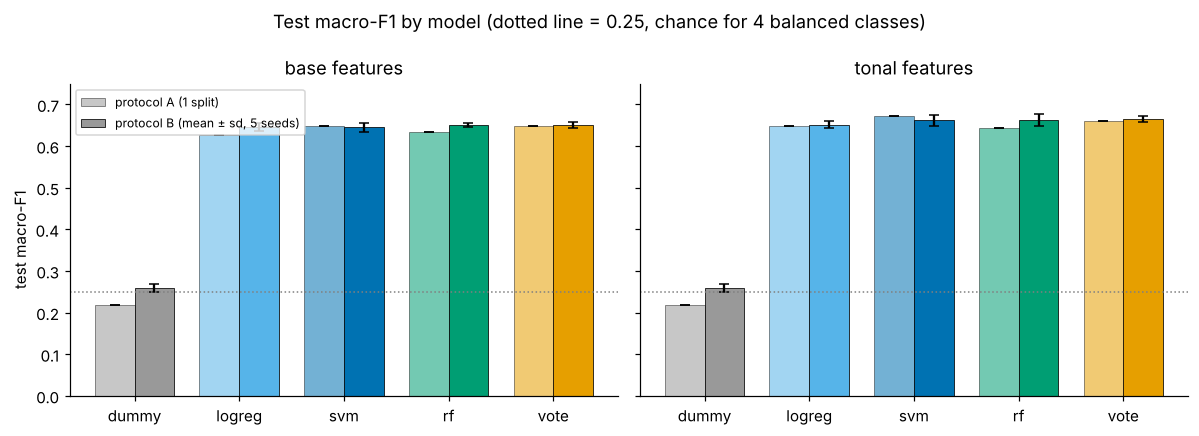

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, fs in zip(axes, ["base", "tonal"]):
    x = np.arange(len(MODELS))
    for k, fam in enumerate(["A", "B"]):
        sub = table[(table.family == fam) & (table.feature_set == fs)].set_index("model").loc[MODELS]
        ax.bar(x + (k - 0.5) * 0.38, sub["mean"], 0.38, yerr=sub["std"].fillna(0), capsize=3,
               color=[MODEL_COLORS[m] for m in MODELS], alpha=0.55 if fam == "A" else 1.0,
               edgecolor="black", linewidth=0.5, label=f"protocol {fam}" + (" (1 split)" if fam == "A" else " (mean ± sd, 5 seeds)"))
    ax.set_xticks(x, MODELS)
    ax.axhline(0.25, color="grey", linestyle=":", linewidth=1)
    ax.set_title(f"{fs} features")
    ax.set_ylim(0, 0.75)
axes[0].set_ylabel("test macro-F1")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Test macro-F1 by model (dotted line = 0.25, chance for 4 balanced classes)")
save(fig, "01_main_comparison")

In [4]:
b = runs[runs.family == "B"]
best_b = b.groupby(["feature_set", "model"])["test_macro_f1"].mean()
summary["chance_B"] = round(float(best_b.loc[("tonal", "dummy")]), 3)
summary["best_B"] = best_b.drop(index="dummy", level="model").idxmax(), round(float(best_b.drop(index="dummy", level="model").max()), 3)
summary["logreg_B_tonal"] = round(float(best_b.loc[("tonal", "logreg")]), 3)
summary

{'chance_B': 0.259,
 'best_B': (('tonal', 'vote'), 0.664),
 'logreg_B_tonal': 0.652}

## 2. Robustness: does the result depend on which artists are in the test set?

**Purpose:** decision D12. With a single artist split, a difference of 0.01–0.02 between two models could come from the particular artists drawn into the test set. Each line below is one model; each point is one seed of protocol B. If the lines cross often, the ranking of the models is not stable; if one line stays above another on every seed, the ranking is robust to the choice of artists.

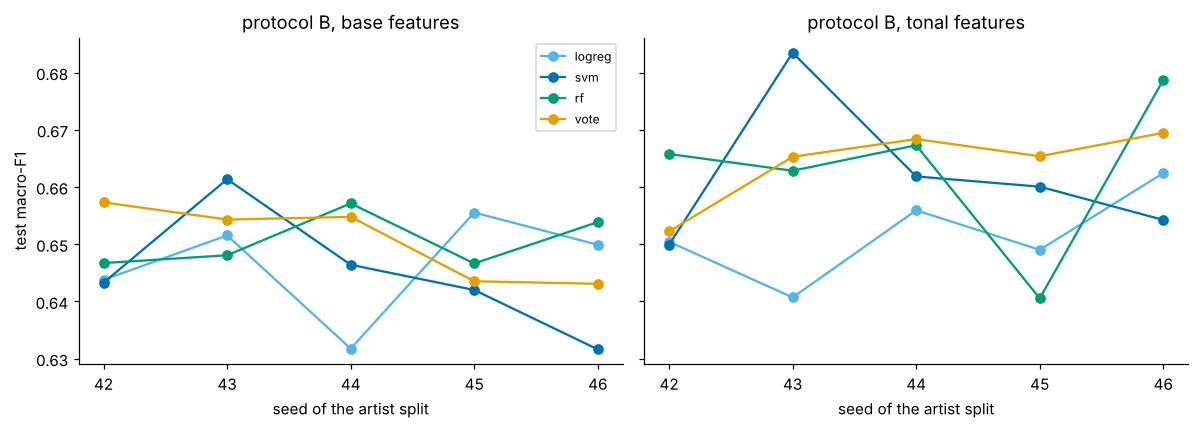

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, fs in zip(axes, ["base", "tonal"]):
    sub = b[b.feature_set == fs]
    for m in ["logreg", "svm", "rf", "vote"]:
        s = sub[sub.model == m].sort_values("protocol")
        ax.plot(s["protocol"].str[1:], s["test_macro_f1"], marker="o", color=MODEL_COLORS[m], label=m)
    ax.set_title(f"protocol B, {fs} features")
    ax.set_xlabel("seed of the artist split")
axes[0].set_ylabel("test macro-F1")
axes[0].legend(fontsize=8)
save(fig, "02_seed_stability")

**Effect of the tonal features, seed by seed.** For each model and seed the difference *tonal − base* is computed on the same test songs. Counting on how many seeds the difference is positive is a simple, assumption-free summary; with five seeds a Wilcoxon signed-rank test cannot reach p < 0.05 (the smallest possible two-sided p is 0.0625), so the count and the mean difference are the honest summary.

In [6]:
paired = b.pivot_table(index=["protocol", "model"], columns="feature_set", values="test_macro_f1").reset_index()
paired["tonal_minus_base"] = paired["tonal"] - paired["base"]
delta = (paired[paired.model != "dummy"].groupby("model")["tonal_minus_base"]
         .agg(mean="mean", std="std", positive=lambda s: int((s > 0).sum()), seeds="count"))
delta.round(4).to_csv(OUT / "02_tonal_minus_base_by_seed.csv")
summary["tonal_gain_B"] = delta["mean"].round(4).to_dict()
delta.round(4)

,mean,std,positive,seeds
model,,,,
logreg,0.0052,0.0142,3,5
rf,0.0126,0.0118,4,5
svm,0.0170,0.0065,5,5
vote,0.0135,0.0121,4,5


## 3. Are the differences statistically significant? (McNemar test)

**Purpose:** two models evaluated on the same test songs can be compared song by song. McNemar's test uses only the songs on which the two models disagree: *b* = songs model 1 gets right and model 2 gets wrong, *c* = the opposite. If the models were equally good, *b* and *c* would be equal up to chance. We use the exact version (a binomial test on *b* out of *b + c*), which is valid even when *b + c* is small.

The test is run separately on every test set (protocol A and each of the five B seeds). A difference that is significant on only one split, or significant in opposite directions on different splits, is not a robust finding.

In [7]:
def mcnemar(frame, left, right):
    l = frame[frame.key == left].set_index("Song")
    r = frame[frame.key == right].set_index("Song").loc[l.index]
    ok_l, ok_r = l["pred"] == l["true"], r["pred"] == r["true"]
    b_, c_ = int((ok_l & ~ok_r).sum()), int((~ok_l & ok_r).sum())
    p = stats.binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0
    return b_, c_, p


preds["key"] = preds["model"] + "_" + preds["feature_set"]
pairs = [("svm_tonal", "rf_tonal"), ("svm_tonal", "logreg_tonal"), ("rf_tonal", "logreg_tonal"),
         ("vote_tonal", "svm_tonal"), ("vote_tonal", "rf_tonal"),
         ("svm_tonal", "svm_base"), ("rf_tonal", "rf_base")]
rows = []
for protocol, frame in preds.groupby("protocol"):
    for left, right in pairs:
        b_, c_, p = mcnemar(frame, left, right)
        rows.append({"protocol": protocol, "comparison": f"{left} vs {right}", "only_left_correct": b_, "only_right_correct": c_, "p_value": p})
mc = pd.DataFrame(rows)
mc.round(4).to_csv(OUT / "03_mcnemar.csv", index=False)
mc_wide = mc.pivot(index="comparison", columns="protocol", values="p_value").loc[[f"{l} vs {r}" for l, r in pairs]]
mc_wide.round(3)

protocol,A,B42,B43,B44,B45,B46
comparison,,,,,,
svm_tonal vs rf_tonal,0.161,0.500,0.374,0.902,0.416,0.248
svm_tonal vs logreg_tonal,0.193,1.000,0.027,0.665,0.621,0.911
rf_tonal vs logreg_tonal,0.844,0.530,0.337,0.581,0.925,0.456
vote_tonal vs svm_tonal,0.359,1.000,0.185,0.581,0.711,0.143
vote_tonal vs rf_tonal,0.328,0.497,1.000,1.000,0.135,0.694
svm_tonal vs svm_base,0.220,0.712,0.262,0.332,0.233,0.262
rf_tonal vs rf_base,0.551,0.243,0.327,0.511,0.883,0.096


In [8]:
sig = mc.assign(sig=mc.p_value < 0.05, left_better=mc.only_left_correct > mc.only_right_correct)
count = sig.groupby("comparison").agg(splits=("sig", "size"), significant=("sig", "sum"), left_better=("left_better", "sum"))
count = count.loc[[f"{l} vs {r}" for l, r in pairs]]
count.to_csv(OUT / "03_mcnemar_summary.csv")
summary["mcnemar_significant_counts"] = count["significant"].to_dict()
count

,splits,significant,left_better
comparison,,,
svm_tonal vs rf_tonal,6,0,3
svm_tonal vs logreg_tonal,6,1,4
rf_tonal vs logreg_tonal,6,0,4
vote_tonal vs svm_tonal,6,0,4
vote_tonal vs rf_tonal,6,0,4
svm_tonal vs svm_base,6,0,6
rf_tonal vs rf_base,6,0,5


**How to read the two tables.** `p_value` < 0.05 means that on that test set the two models disagree in a lopsided way that is unlikely under equal accuracy. `left_better` counts on how many of the six test sets the first model wins more of the disagreements, regardless of significance. A comparison that is never significant but where one side wins on most splits suggests a small, consistent effect that a single test set of ~460–490 songs is too small to confirm.

## 4. Hyperparameters: how sensitive are the models?

**Purpose:** show that the chosen hyperparameters are not a lucky point and that the search range was wide enough (the best value should not sit on the edge of the grid). The heatmap shows validation macro-F1 of the SVM for every value of C and gamma that was tried; the bar chart shows the same for the Random Forest settings. Both are for the tonal feature set, protocol A and protocol B seed 42.

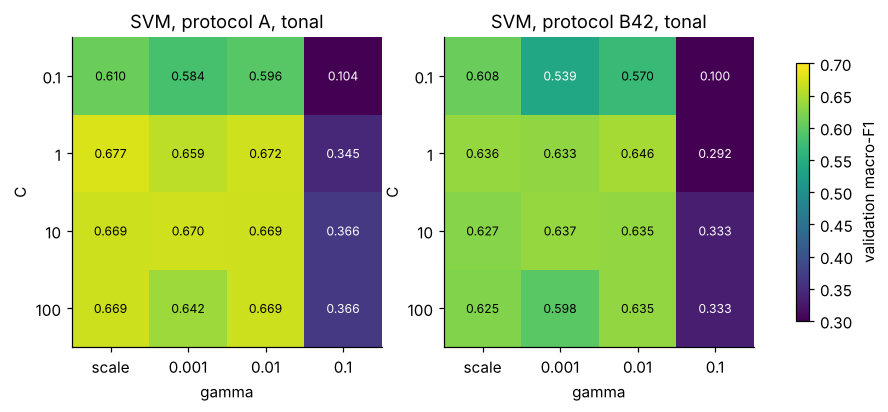

In [9]:
svm_s = search[(search.model == "svm") & (search.feature_set == "tonal") & search.protocol.isin(["A", "B42"])].copy()
gamma_order = ["scale", "0.001", "0.01", "0.1"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, protocol in zip(axes, ["A", "B42"]):
    grid = (svm_s[svm_s.protocol == protocol]
            .assign(C=lambda d: d.C.astype(float), gamma=lambda d: d.gamma.astype(str))
            .pivot(index="C", columns="gamma", values="val_macro_f1")[gamma_order])
    im = ax.imshow(grid.values, cmap="viridis", vmin=0.3, vmax=0.7)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center", color="white" if grid.values[i, j] < 0.55 else "black", fontsize=8)
    ax.set_xticks(range(len(gamma_order)), gamma_order)
    ax.set_yticks(range(grid.shape[0]), [f"{c:g}" for c in grid.index])
    ax.set_xlabel("gamma")
    ax.set_ylabel("C")
    ax.set_title(f"SVM, protocol {protocol}, tonal")
fig.colorbar(im, ax=axes, shrink=0.8, label="validation macro-F1")
fig.savefig(OUT / "04_svm_grid.png", bbox_inches="tight")
plt.show()

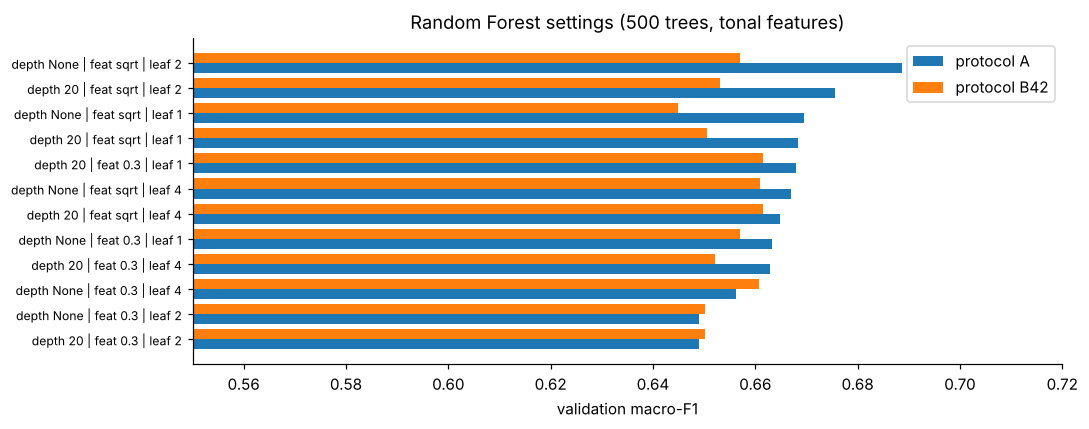

In [10]:
rf_s = search[(search.model == "rf") & (search.feature_set == "tonal") & search.protocol.isin(["A", "B42"])].copy()
rf_s["setting"] = "depth " + rf_s.max_depth.map(lambda v: "None" if pd.isna(v) else str(int(v))) + " | feat " + rf_s.max_features.astype(str) + " | leaf " + rf_s.min_samples_leaf.astype(float).astype(int).astype(str)
fig, ax = plt.subplots(figsize=(10, 4))
order = rf_s[rf_s.protocol == "A"].sort_values("val_macro_f1")["setting"]
for k, protocol in enumerate(["A", "B42"]):
    s = rf_s[rf_s.protocol == protocol].set_index("setting").loc[order]
    ax.barh(np.arange(len(order)) + (k - 0.5) * 0.4, s["val_macro_f1"], 0.4, label=f"protocol {protocol}")
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.set_xlim(0.55, 0.72)
ax.set_xlabel("validation macro-F1")
ax.set_title("Random Forest settings (500 trees, tonal features)")
ax.legend()
save(fig, "04_rf_grid")

In [11]:
chosen = runs[runs.model.isin(["logreg", "svm", "rf"])][["protocol", "feature_set", "model", "best_params"]]
chosen.to_csv(OUT / "04_chosen_hyperparameters.csv", index=False)
chosen.pivot_table(index=["model", "feature_set"], columns="protocol", values="best_params", aggfunc="first")

protocol                                                            A  \
model  feature_set                                                      
logreg base                                             {"C": "0.01"}   
       tonal                                            {"C": "0.01"}   
rf     base         {"n_estimators": "500", "max_depth": "20", "ma...   
       tonal        {"n_estimators": "500", "max_depth": "None", "...   
svm    base                              {"C": "1", "gamma": "scale"}   
       tonal                             {"C": "1", "gamma": "scale"}   

protocol                                                          B42  \
model  feature_set                                                      
logreg base                                                {"C": "1"}   
       tonal                                            {"C": "0.01"}   
rf     base         {"n_estimators": "500", "max_depth": "None", "...   
       tonal        {"n_estimators": "500", "max_depth": "20", "ma...   
svm    base                              {"C": "10", "gamma": "0.01"}   
       tonal                              {"C": "1", "gamma": "0.01"}   

protocol                                                          B43  \
model  feature_set                                                      
logreg base                                              {"C": "0.1"}   
       tonal                                            {"C": "0.01"}   
rf     base         {"n_estimators": "500", "max_depth": "None", "...   
       tonal        {"n_estimators": "500", "max_depth": "None", "...   
svm    base                              {"C": "1", "gamma": "scale"}   
       tonal                              {"C": "1", "gamma": "0.01"}   

protocol                                                          B44  \
model  feature_set                                                      
logreg base                                             {"C": "0.01"}   
       tonal                                            {"C": "0.01"}   
rf     base         {"n_estimators": "500", "max_depth": "None", "...   
       tonal        {"n_estimators": "500", "max_depth": "20", "ma...   
svm    base                              {"C": "1", "gamma": "0.001"}   
       tonal                             {"C": "1", "gamma": "0.001"}   

protocol                                                          B45  \
model  feature_set                                                      
logreg base                                               {"C": "10"}   
       tonal                                               {"C": "1"}   
rf     base         {"n_estimators": "500", "max_depth": "20", "ma...   
       tonal        {"n_estimators": "500", "max_depth": "20", "ma...   
svm    base                              {"C": "1", "gamma": "scale"}   
       tonal                             {"C": "1", "gamma": "scale"}   

protocol                                                          B46  
model  feature_set                                                     
logreg base                                             {"C": "0.01"}  
       tonal                                               {"C": "1"}  
rf     base         {"n_estimators": "500", "max_depth": "20", "ma...  
       tonal        {"n_estimators": "500", "max_depth": "None", "...  
svm    base                              {"C": "1", "gamma": "scale"}  
       tonal                             {"C": "1", "gamma": "scale"}

## 5. Overfitting: training vs validation vs test

**Purpose:** a large gap between training and validation scores means the model memorises the training songs. Random Forests reach ~1.0 on training data by construction (fully grown trees), so the gap is expected for them and is not by itself a problem; what matters is that validation and test agree, which shows that selecting on validation did not overfit the validation set.

In [12]:
gap = (runs[runs.model.isin(["logreg", "svm", "rf"])]
       .groupby(["family", "feature_set", "model"])[["train_macro_f1", "val_macro_f1", "test_macro_f1"]].mean())
gap["train_minus_test"] = gap["train_macro_f1"] - gap["test_macro_f1"]
gap["val_minus_test"] = gap["val_macro_f1"] - gap["test_macro_f1"]
gap.round(3).to_csv(OUT / "05_train_val_test.csv")
gap.round(3)

train_macro_f1  val_macro_f1  test_macro_f1  \
family feature_set model                                                 
A      base        logreg           0.700         0.649          0.627   
                   rf               1.000         0.663          0.634   
                   svm              0.858         0.681          0.648   
       tonal       logreg           0.711         0.660          0.649   
                   rf               0.999         0.689          0.644   
                   svm              0.866         0.677          0.671   
B      base        logreg           0.714         0.641          0.646   
                   rf               1.000         0.661          0.650   
                   svm              0.847         0.656          0.645   
       tonal       logreg           0.729         0.652          0.652   
                   rf               1.000         0.660          0.663   
                   svm              0.854         0.655          0.662   

                           train_minus_test  val_minus_test  
family feature_set model                                     
A      base        logreg             0.073           0.022  
                   rf                 0.366           0.029  
                   svm                0.209           0.033  
       tonal       logreg             0.062           0.012  
                   rf                 0.355           0.045  
                   svm                0.195           0.006  
B      base        logreg             0.067          -0.006  
                   rf                 0.349           0.010  
                   svm                0.202           0.011  
       tonal       logreg             0.077           0.001  
                   rf                 0.337          -0.003  
                   svm                0.192          -0.007

## 6. Learning curve: would more data help?

**Purpose:** each model (tonal features, protocol A, hyperparameters chosen in §4) is retrained on 10 %, 20 %, 40 %, 60 % and 80 % of the training songs, sampled with the class balance preserved and repeated five times, plus once on 100 %. The score is measured on the validation set. If the validation curve is still rising at 100 %, more training data would likely help; if it has flattened, the limit is in the features or the labels rather than in the amount of data.

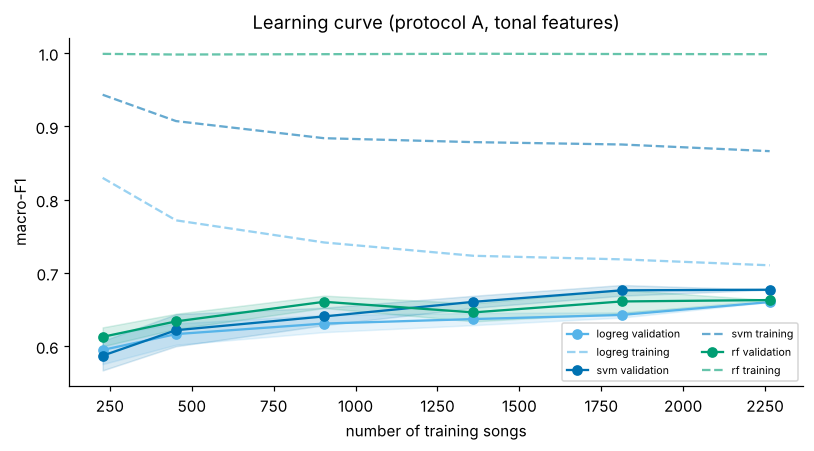

model,rf,svm
n_train,,
228,0.613,0.587
452,0.634,0.622
904,0.661,0.641
1360,0.646,0.661
1812,0.661,0.676
2264,0.663,0.677


In [13]:
lc = pd.read_csv(EXP / "learning_curve_validation.csv")
agg = lc.groupby(["model", "n_train"]).agg(train=("train_macro_f1", "mean"), val=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std")).reset_index()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in ["logreg", "svm", "rf"]:
    s = agg[agg.model == m]
    ax.plot(s.n_train, s.val, marker="o", color=MODEL_COLORS[m], label=f"{m} validation")
    ax.fill_between(s.n_train, s.val - s.val_sd.fillna(0), s.val + s.val_sd.fillna(0), color=MODEL_COLORS[m], alpha=0.15)
    ax.plot(s.n_train, s.train, linestyle="--", color=MODEL_COLORS[m], alpha=0.6, label=f"{m} training")
ax.set_xlabel("number of training songs")
ax.set_ylabel("macro-F1")
ax.set_title("Learning curve (protocol A, tonal features)")
ax.legend(fontsize=7, ncol=2)
save(fig, "06_learning_curve")
agg.round(3).to_csv(OUT / "06_learning_curve.csv", index=False)
agg[agg.model != "logreg"].pivot(index="n_train", columns="model", values="val").round(3)

## 7. Which groups of features matter? (ablation on validation)

**Purpose:** Random Forest importances (saved by `train_classic.py`) say which features the forest *uses*, but correlated features share importance and the SVM has no importances at all. Ablation answers a more direct question: *how much does the validation score drop if a whole group of features is removed and the model is retrained?* A large drop means the group carries information the others do not; no drop means the information is redundant.

The groups are: MFCC (timbre), MFCC deltas (timbre change), spectral shape (centroid, bandwidth, roll-off, flatness), spectral contrast, energy and noisiness (RMS, ZCR), chroma, rhythm (tempo, onset strength), mode and key (modality, key clarity and strength), tonnetz and harmonic change. Hyperparameters are kept at the values chosen in §4.

**Caveat:** each number comes from one validation set of ~480 songs, so differences of about ±0.01–0.02 are within normal variation. Only consistent and large drops should be interpreted.

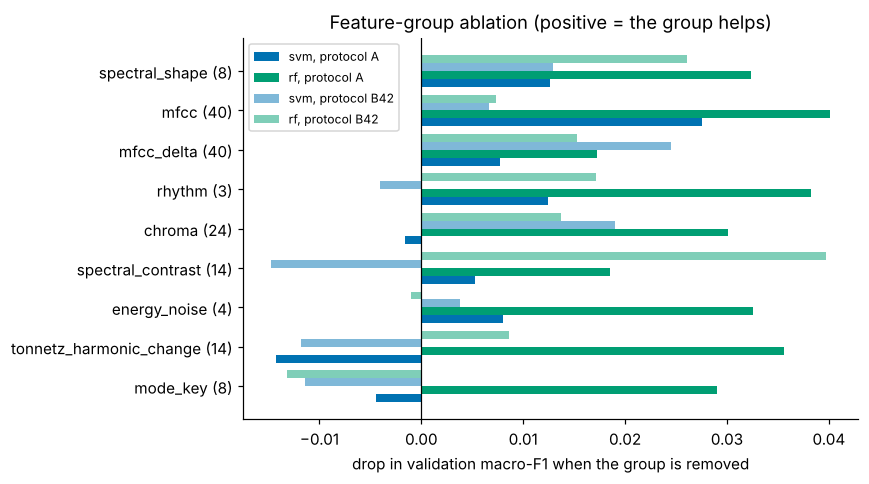

protocol                     A           B42        mean_drop
model                       rf    svm     rf    svm          
removed_group                                                
spectral_shape           0.032  0.013  0.026  0.013     0.021
mfcc                     0.040  0.028  0.007  0.007     0.020
mfcc_delta               0.017  0.008  0.015  0.025     0.016
rhythm                   0.038  0.012  0.017 -0.004     0.016
chroma                   0.030 -0.002  0.014  0.019     0.015
spectral_contrast        0.019  0.005  0.040 -0.015     0.012
energy_noise             0.033  0.008 -0.001  0.004     0.011
tonnetz_harmonic_change  0.036 -0.014  0.009 -0.012     0.005
mode_key                 0.029 -0.004 -0.013 -0.011    -0.000

In [14]:
ab = pd.read_csv(EXP / "ablation_validation.csv")
full = ab[ab.removed_group == "none"].set_index(["protocol", "model"])["val_macro_f1"]
ab["drop"] = ab.apply(lambda r: full.loc[(r.protocol, r.model)] - r.val_macro_f1, axis=1)
ab_g = ab[ab.removed_group != "none"]
order = ab_g.groupby("removed_group")["drop"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.5))
combos = [("A", "svm"), ("A", "rf"), ("B42", "svm"), ("B42", "rf")]
for k, (p, m) in enumerate(combos):
    s = ab_g[(ab_g.protocol == p) & (ab_g.model == m)].set_index("removed_group").loc[order]
    ax.barh(np.arange(len(order)) + (k - 1.5) * 0.2, s["drop"], 0.2, label=f"{m}, protocol {p}",
            color=MODEL_COLORS[m], alpha=1.0 if p == "A" else 0.5)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(range(len(order)), [f"{g} ({int(ab_g[ab_g.removed_group == g].n_removed.iloc[0])})" for g in order])
ax.set_xlabel("drop in validation macro-F1 when the group is removed")
ax.set_title("Feature-group ablation (positive = the group helps)")
ax.legend(fontsize=8)
save(fig, "07_ablation")
ab_table = ab_g.pivot_table(index="removed_group", columns=["protocol", "model"], values="drop").loc[order[::-1]]
ab_table["mean_drop"] = ab_table.mean(axis=1)
ab_table.round(3).to_csv(OUT / "07_ablation.csv")
ab_table.round(3)

## 8. Does combining the models help? (ensemble)

**Purpose:** SVM, Random Forest and logistic regression make different kinds of errors, so a majority vote might correct some of them. Whether to use the ensemble must be decided on validation, not on test. The first table compares, on validation, the vote with the best single model of the same split; the second shows the test scores for reference only.

In [15]:
ens = pd.read_csv(EXP / "ensemble_validation.csv")
ens["vote_minus_best_single"] = ens["val_macro_f1_vote"] - ens["val_macro_f1_best_single"]
ens.round(4).to_csv(OUT / "08_ensemble_validation.csv", index=False)
summary["vote_beats_best_single_on_val"] = f"{int((ens.vote_minus_best_single > 0).sum())} of {len(ens)}"
display(ens.round(4))
test_cmp = runs[runs.model.isin(["svm", "rf", "vote"])].pivot_table(index=["protocol", "feature_set"], columns="model", values="test_macro_f1")
test_cmp.round(4)

,protocol,feature_set,val_macro_f1_vote,val_macro_f1_best_single,vote_minus_best_single
0,A,base,0.6793,0.6811,-0.0018
1,A,tonal,0.6788,0.6887,-0.0099
2,B42,base,0.6918,0.6704,0.0214
3,B42,tonal,0.6643,0.6615,0.0028
4,B43,base,0.6566,0.6434,0.0133
5,B43,tonal,0.6718,0.6837,-0.0118
6,B44,base,0.6646,0.6663,-0.0017
7,B44,tonal,0.6783,0.6715,0.0068
8,B45,base,0.6680,0.6660,0.0020
9,B45,tonal,0.6713,0.6725,-0.0013


model                     rf     svm    vote
protocol feature_set                        
A        base         0.6343  0.6483  0.6473
         tonal        0.6436  0.6710  0.6611
B42      base         0.6467  0.6433  0.6573
         tonal        0.6658  0.6499  0.6522
B43      base         0.6481  0.6614  0.6543
         tonal        0.6628  0.6835  0.6653
B44      base         0.6571  0.6464  0.6548
         tonal        0.6673  0.6618  0.6684
B45      base         0.6466  0.6420  0.6435
         tonal        0.6405  0.6601  0.6654
B46      base         0.6539  0.6316  0.6431
         tonal        0.6787  0.6542  0.6695

## 9. Error analysis: which songs are confused, and is genre involved?

**Purpose:** the overall score hides where the errors are. The confusion matrix below pools the test predictions of the five protocol-B seeds for the tonal SVM and the tonal RF (each test song of each seed counted once per seed), normalised by row: each row shows how the songs of one true quadrant were classified.

Then the Q3/Q4 errors (the main weakness identified in `01_eda.ipynb` and `03_valence_features.ipynb`) are broken down by the song's main genre (first genre listed in the metadata column `Genres`). If errors concentrated in one genre, the problem could be genre-specific; if they follow the genre mix of the test sets, the problem is general.

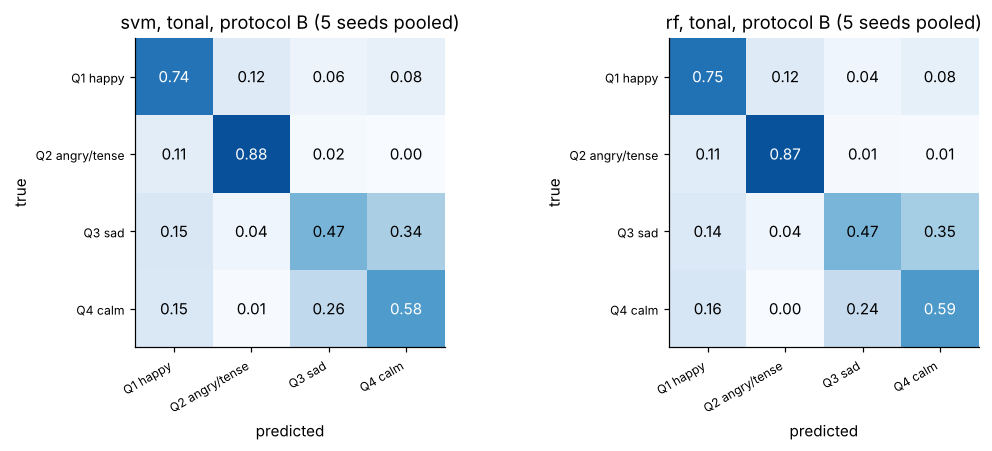

test_f1_Q1        test_f1_Q2        test_f1_Q3        test_f1_Q4       
             mean    std       mean    std       mean    std       mean    std
model                                                                         
logreg      0.684  0.015      0.838  0.021      0.526  0.035      0.559  0.022
rf          0.691  0.031      0.853  0.007      0.527  0.056      0.580  0.010
svm         0.691  0.029      0.855  0.024      0.520  0.032      0.582  0.015
vote        0.695  0.037      0.856  0.016      0.522  0.033      0.584  0.016

In [16]:
b_preds = preds[(preds.protocol != "A") & (preds.feature_set == "tonal")]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, m in zip(axes, ["svm", "rf"]):
    s = b_preds[b_preds.model == m]
    cm = confusion_matrix(s["true"], s["pred"], labels=QUADRANTS, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(4), [NAMES[q] for q in QUADRANTS], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(4), [NAMES[q] for q in QUADRANTS], fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{m}, tonal, protocol B (5 seeds pooled)")
save(fig, "09_confusion_B_pooled")
per_class = runs[(runs.family == "B") & (runs.feature_set == "tonal") & runs.model.isin(["logreg", "svm", "rf", "vote"])]
per_class = per_class.groupby("model")[[f"test_f1_{q}" for q in QUADRANTS]].agg(["mean", "std"])
per_class.round(3).to_csv(OUT / "09_per_class_f1_B.csv")
per_class.round(3)

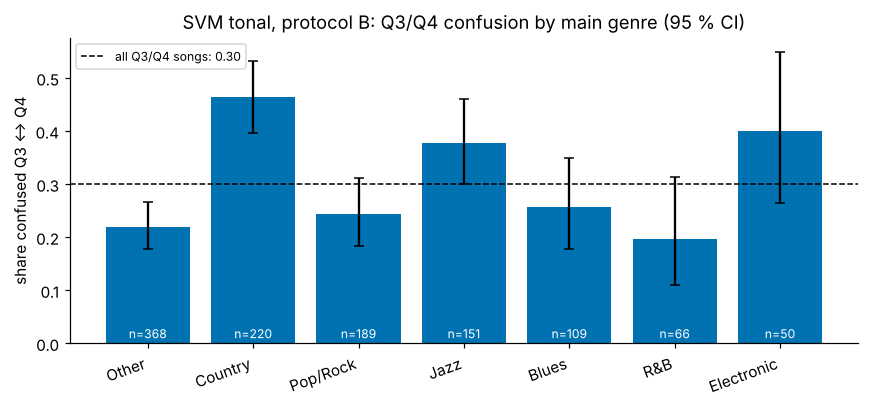

chi-square test, genre x confused: p = 0.0000


,songs,q3_q4_confusion_rate,share_Q3,ci_low,ci_high
Genre,,,,,
Other,368,0.220,0.348,0.179,0.266
Country,220,0.464,0.577,0.396,0.532
Pop/Rock,189,0.243,0.683,0.184,0.311
Jazz,151,0.377,0.397,0.300,0.460
Blues,109,0.257,0.798,0.178,0.349
R&B,66,0.197,0.348,0.109,0.313
Electronic,50,0.400,0.460,0.264,0.548


In [17]:
meta = pd.read_csv(META, usecols=["Song", "Artist", "Title", "Genres"])
meta["MainGenre"] = meta["Genres"].fillna("Unknown").str.split(",").str[0]
low = b_preds[(b_preds.model == "svm") & b_preds.true.isin(["Q3", "Q4"])].merge(meta, on="Song")
low["confused"] = low["pred"].isin(["Q3", "Q4"]) & (low["pred"] != low["true"])
top = low["MainGenre"].value_counts().head(6).index
low["Genre"] = np.where(low["MainGenre"].isin(top), low["MainGenre"], "Other")
by_genre = low.groupby("Genre").agg(songs=("confused", "size"), q3_q4_confusion_rate=("confused", "mean"),
                                    share_Q3=("true", lambda s: (s == "Q3").mean())).sort_values("songs", ascending=False)
overall = low["confused"].mean()
table_g = by_genre.assign(ci_low=lambda d: [stats.binomtest(int(round(r * n)), n).proportion_ci().low for r, n in zip(d.q3_q4_confusion_rate, d.songs)],
                          ci_high=lambda d: [stats.binomtest(int(round(r * n)), n).proportion_ci().high for r, n in zip(d.q3_q4_confusion_rate, d.songs)])
table_g.round(3).to_csv(OUT / "09_q3_q4_confusion_by_genre.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(table_g.index, table_g.q3_q4_confusion_rate, yerr=[table_g.q3_q4_confusion_rate - table_g.ci_low, table_g.ci_high - table_g.q3_q4_confusion_rate],
       capsize=3, color="#0072B2")
ax.axhline(overall, color="black", linestyle="--", linewidth=1, label=f"all Q3/Q4 songs: {overall:.2f}")
for i, n in enumerate(table_g.songs):
    ax.text(i, 0.01, f"n={n}", ha="center", color="white", fontsize=8)
ax.set_ylabel("share confused Q3 ↔ Q4")
ax.set_title("SVM tonal, protocol B: Q3/Q4 confusion by main genre (95 % CI)")
ax.legend(fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save(fig, "09_q3_q4_by_genre")
chi = stats.chi2_contingency(pd.crosstab(low["Genre"], low["confused"]))
summary["q3q4_genre_chi2_p"] = round(float(chi.pvalue), 4)
print(f"chi-square test, genre x confused: p = {chi.pvalue:.4f}")
table_g.round(3)

The columns: `songs` = Q3 and Q4 test songs of that genre over the five seeds; `q3_q4_confusion_rate` = share of them classified as the other low-arousal quadrant; `share_Q3` = share of them that are truly sad, which matters because a genre that is mostly Q3 or mostly Q4 can push the model towards one answer. The chi-square test checks whether the confusion rate differs between genres more than chance would explain. **Caveat:** the five seeds have different but overlapping test sets, so some songs are counted more than once; the test therefore treats the rows as more independent than they are and its p-value is optimistic. The ordering of the genres and the size of the gaps are the more reliable part of this result.

In [18]:
consistent = (b_preds[b_preds.model == "svm"].assign(wrong=lambda d: d.pred != d.true)
              .groupby("Song").agg(seeds=("wrong", "size"), wrong=("wrong", "sum"), true=("true", "first"),
                                   most_common_pred=("pred", lambda s: s.mode().iloc[0])))
hard = consistent[(consistent.seeds >= 2) & (consistent.wrong == consistent.seeds)].merge(meta, left_index=True, right_on="Song")
hard[["Song", "Artist", "Title", "MainGenre", "true", "most_common_pred", "seeds"]].to_csv(OUT / "09_always_wrong_songs.csv", index=False)
print(f"{len(hard)} songs appear in the test set of at least two seeds and are misclassified every time")
pd.crosstab(hard["true"], hard["most_common_pred"])

147 songs appear in the test set of at least two seeds and are misclassified every time


most_common_pred,Q1,Q2,Q3,Q4
true,,,,
Q1,0,11,8,10
Q2,13,0,1,0
Q3,23,7,0,30
Q4,15,1,28,0


Songs that land in the test set under several seeds and are *always* misclassified are the natural candidates for listening checks: some may be genuinely ambiguous, some may carry a questionable label. `09_always_wrong_songs.csv` lists them with artist and title so that a few can be listened to and discussed in the thesis.

## 10. Confidence: ROC curves and AUC (protocol A, tonal)

**Purpose:** macro-F1 evaluates the single predicted class. ROC curves use the model's scores for every class (probabilities for RF and logistic regression, decision-function values for the SVM) and show, for each quadrant treated one-vs-rest, the trade-off between detecting the songs of that quadrant and raising false alarms at every possible threshold. AUC = 1 is perfect ranking, 0.5 is chance. This shows whether a quadrant is hard because the model ranks it badly or only because the decision threshold falls in the wrong place.

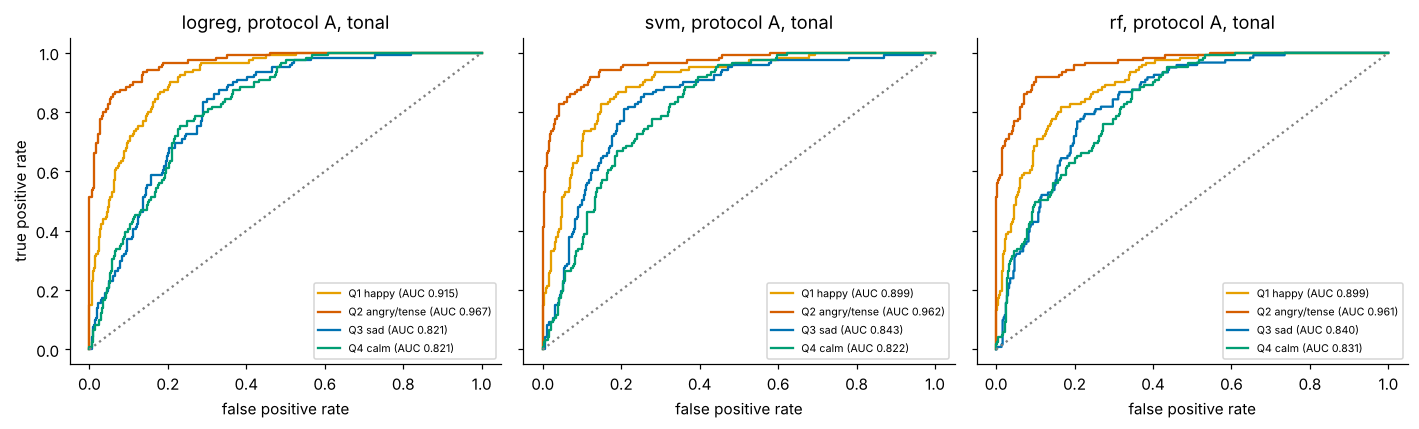

model,logreg,rf,svm
quadrant,,,
Q1,0.915,0.899,0.899
Q2,0.967,0.961,0.962
Q3,0.821,0.840,0.843
Q4,0.821,0.831,0.822
macro,0.881,0.883,0.882


In [19]:
roc = pd.read_csv(EXP / "roc_scores_protocol_A.csv")
roc = roc[roc.feature_set == "tonal"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
auc_rows = []
for ax, m in zip(axes, ["logreg", "svm", "rf"]):
    s = roc[roc.model == m]
    for q, color in zip(QUADRANTS, ["#E69F00", "#D55E00", "#0072B2", "#009E73"]):
        fpr, tpr, _ = roc_curve(s["true"] == q, s[f"score_{q}"])
        a = auc(fpr, tpr)
        auc_rows.append({"model": m, "quadrant": q, "auc": a})
        ax.plot(fpr, tpr, color=color, label=f"{NAMES[q]} (AUC {a:.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":")
    ax.set_title(f"{m}, protocol A, tonal")
    ax.set_xlabel("false positive rate")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("true positive rate")
save(fig, "10_roc_protocol_A")
aucs = pd.DataFrame(auc_rows).pivot(index="quadrant", columns="model", values="auc")
aucs.loc["macro"] = aucs.mean()
aucs.round(3).to_csv(OUT / "10_auc.csv")
aucs.round(3)

## 11. Cost: training time, prediction time and model size

**Purpose:** the models will be used by the interface, so their cost matters. Training time and size are measured by `experiments_classic.py` for the final fit with the chosen hyperparameters (size = bytes of the pickled model). Prediction time is measured here by refitting the protocol-A tonal models and timing the prediction of the whole test set. Times depend on the machine (see `info.json`), so only their order of magnitude should be compared.

In [20]:
import sys, time
sys.path.insert(0, str(ROOT / "src"))
from experiments_classic import make, load_split, splits as split_defs, best_params_for
from train_classic import load_features

data, cols = load_features("tonal")
name, folder = split_defs()["A"]
ids = load_split(name, folder)
Xtr, ytr = data.loc[ids["train"], cols].to_numpy(), data.loc[ids["train"], "Quadrant"].to_numpy()
Xte = data.loc[ids["test"], cols].to_numpy()
rows = []
for m in ["logreg", "svm", "rf"]:
    model = make(m, best_params_for(runs, "A", "tonal", m)).fit(Xtr, ytr)
    t0 = time.perf_counter()
    for _ in range(5):
        model.predict(Xte)
    per_song = (time.perf_counter() - t0) / 5 / len(Xte)
    r = runs[(runs.protocol == "A") & (runs.feature_set == "tonal") & (runs.model == m)].iloc[0]
    rows.append({"model": m, "fit_seconds": r.fit_seconds, "predict_ms_per_song": per_song * 1000, "size_MB": r.model_bytes / 1e6,
                 "test_macro_f1": r.test_macro_f1})
cost = pd.DataFrame(rows).set_index("model")
cost.round(4).to_csv(OUT / "11_cost.csv")
cost.round(4)

,fit_seconds,predict_ms_per_song,size_MB,test_macro_f1
model,,,,
logreg,0.0529,0.0039,0.0098,0.6486
svm,0.2597,0.5064,2.3411,0.6710
rf,5.0892,0.3998,27.8151,0.6436


Prediction time here excludes feature extraction. For a new song in the interface, extracting the 155 features from 30 s of audio takes far longer than the classifier itself (`features.py` and `features_tonal.py` together needed about 16 minutes for 3,232 clips, i.e. roughly 0.3 s per clip on the laptop), so the choice between the classifiers should not be driven by their prediction time.

## 12. Summary of the numbers used in the findings

In [21]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
summary

{'chance_B': 0.259,
 'best_B': (('tonal', 'vote'), 0.664),
 'logreg_B_tonal': 0.652,
 'tonal_gain_B': {'logreg': 0.0052,
  'rf': 0.0126,
  'svm': 0.017,
  'vote': 0.0135},
 'mcnemar_significant_counts': {'svm_tonal vs rf_tonal': 0,
  'svm_tonal vs logreg_tonal': 1,
  'rf_tonal vs logreg_tonal': 0,
  'vote_tonal vs svm_tonal': 0,
  'vote_tonal vs rf_tonal': 0,
  'svm_tonal vs svm_base': 0,
  'rf_tonal vs rf_base': 0},
 'vote_beats_best_single_on_val': '6 of 12',
 'q3q4_genre_chi2_p': 0.0}

## 13. Findings

Numbers below come from the tables above (`results/experiments/figures/`). *Protocol B* means mean ± standard deviation over the five artist splits.

**1. All models are far above chance, and the non-linear models add little over a linear one.** The chance-level classifier scores 0.26 ± 0.01 (protocol B). Logistic regression already reaches 0.652 ± 0.008 with the tonal features; SVM (0.662 ± 0.013), Random Forest (0.663 ± 0.014) and the vote (0.664 ± 0.007) are about 0.01 higher. Most of what the classical models can learn from these features is therefore already captured by a linear boundary.

**2. SVM, Random Forest and the vote are statistically indistinguishable.** Their protocol-B means differ by at most 0.002, which is much smaller than the seed-to-seed standard deviation (≈ 0.013). McNemar's test finds no significant difference between SVM and RF on any of the six test sets, and SVM wins more of the disagreements on only 3 of 6. The thesis should therefore not claim that one classical model is better than the other; both can serve as the classical reference for the CNN.

**3. The tonal features give a small but consistent gain.** With the same test songs, adding the 22 tonal features improves the SVM on 5 of 5 artist splits (mean +0.017 ± 0.007) and the RF on 4 of 5 (+0.013 ± 0.012), and both on protocol A. No single test set is large enough for this gain to be significant by McNemar's test, but its consistency across splits supports decision D13 (keep the tonal block). The ablation (§7) agrees only partly: removing *mode and key* or *tonnetz and harmonic change* lowers the RF score on protocol A but not the SVM score, so the gain should be described as small and model-dependent, not as a solved problem.

**4. The ranking is stable with respect to which artists are tested (D12).** All protocol-B standard deviations are between 0.005 and 0.014. Protocol A lies within about two protocol-B standard deviations of the protocol-B mean for every model, confirming the earlier observation that, for the classical models on these features, the artist effect is small.

**5. Hyperparameters are not a lucky point.** For the SVM a broad plateau of C ∈ {1, 10, 100} with gamma ≤ 0.01 or `scale` gives validation scores mostly within 0.03 of the best (worst corner 0.05 below); only gamma = 0.1 (too narrow a kernel) fails. The RF settings span about 0.04. Validation and test agree closely (mean |validation − test| ≤ 0.045 on A, ≤ 0.011 on B), so selecting on validation did not overfit it.

**6. More data of the same kind would help only a little.** The validation score of the SVM rises from 0.59 with 10 % of the training songs to 0.68 with 100 %, but the last 40 % add only about 0.016, and the RF curve is flat after 40 %. The limit lies mainly in what the features capture, which motivates learning representations directly from spectrograms (the CNN).

**7. No single feature group is indispensable.** Removing any group changes validation macro-F1 by at most 0.04 and the average drop is ≤ 0.021 (largest for spectral shape, MFCC and MFCC deltas). Information is spread over correlated groups, which is consistent with the RF importances being dominated by spectral contrast and MFCC without any one feature being decisive.

**8. The ensemble does not justify its extra cost.** On validation, the vote beats the best single model in 6 of 12 configurations, i.e. no better than a coin flip. Its test scores are similar to those of the best single model. The final classical model therefore stays a single model; the vote is reported as a tried and rejected option.

**9. The main weakness is still Q3 vs Q4, and it is linked to genre.** Per-class F1 on protocol B (SVM tonal) is 0.86 for Q2, 0.69 for Q1, but only 0.58 for Q4 and 0.52 for Q3. ROC AUC tells the same story: about 0.96 for Q2 but 0.82–0.84 for Q3 and Q4. In the pooled protocol-B predictions, 30 % of the Q3 and Q4 songs are classified as the other low-arousal quadrant, but the rate is about 46 % for Country and 38 % for Jazz against about 20–25 % for Pop/Rock, Blues, R&B and the remaining genres. Country is not one-sided (58 % of its Q3/Q4 songs are Q3), so the confusion is not explained by an unbalanced genre. A plausible reading, to be checked by listening to examples in `09_always_wrong_songs.csv`, is that sad and calm songs in these genres share instrumentation and tempo, and that what distinguishes them is lyrical or harmonic detail that the averaged features do not capture.

**10. Cost is not a deciding factor among the classical models.** The SVM trains in ≈ 0.3 s, takes ≈ 2.3 MB and predicts in ≈ 0.5 ms per song; the RF needs ≈ 5 s and ≈ 28 MB. Both are negligible compared to feature extraction (≈ 0.3 s per clip). For the interface the SVM is the more practical classical model (smaller file, same accuracy).

**Consequences for the next steps.** (a) The classical baseline to beat is ≈ 0.66 macro-F1 on unseen artists. (b) Any CNN improvement smaller than ≈ 0.015 must be checked across several seeds before it is claimed. (c) Q3/Q4, especially Country and Jazz, is where the CNN analysis should look first.